## 1. Data Loading & Initial Inspection

**Dataset:** US Airport Traffic (February 2011).
We have 221 airports, their geographic coordinates (lat, long), and the volume of traffic (`cnt`).
**Observations:** 
- The dataset is quite clean, with only 1 missing value in `city` and `state`.
- The target variable for analysis is `cnt` (number of flights/aircraft).

In [8]:
# 1. IMPORTACIÓN DE LIBRERÍAS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import os

# Configuración visual
sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)

# 2. CARGA DE DATOS
url = "https://raw.githubusercontent.com/plotly/datasets/master/2011_february_us_airport_traffic.csv"
df = pd.read_csv(url)

# 3. LIMPIEZA DE DATOS
# Eliminamos nulos y creamos df_clean (así ya existe para todas las demás celdas)
df_clean = df.dropna().copy()

# 4. AGRUPACIONES BÁSICAS (Para no repetir código abajo)
top_airports = df_clean.sort_values(by='cnt', ascending=False).head(10)
df_states = df_clean.groupby('state')['cnt'].sum().reset_index()

print("✅ Entorno listo. Datos cargados y limpios.")
print(f"Filas: {df_clean.shape[0]}")

✅ Entorno listo. Datos cargados y limpios.
Filas: 220


In [9]:
# 1. Limpieza: Eliminar las filas con valores nulos
df_clean = df.dropna().copy()

# 2. Análisis Univariado: Estadísticas descriptivas de la variable objetivo (cnt)
print("--- Estadísticas del Tráfico Aéreo (cnt) ---")
print(df_clean['cnt'].describe())

# 3. Top 10 aeropuertos con más tráfico
top_airports = df_clean.sort_values(by='cnt', ascending=False).head(10)
print("\n--- Top 10 Aeropuertos con más tráfico ---")
print(top_airports[['airport', 'city', 'state', 'cnt']].to_string(index=False))

--- Estadísticas del Tráfico Aéreo (cnt) ---
count      220.000000
mean      2007.377273
std       3757.945949
min         23.000000
25%        191.250000
50%        497.500000
75%       1645.500000
max      25129.000000
Name: cnt, dtype: float64

--- Top 10 Aeropuertos con más tráfico ---
                          airport              city state   cnt
     Chicago O'Hare International           Chicago    IL 25129
William B Hartsfield-Atlanta Intl           Atlanta    GA 21925
  Dallas-Fort Worth International Dallas-Fort Worth    TX 20662
 Phoenix Sky Harbor International           Phoenix    AZ 17290
                      Denver Intl            Denver    CO 13781
     George Bush Intercontinental           Houston    TX 13223
      San Francisco International     San Francisco    CA 12016
        Los Angeles International       Los Angeles    CA 11797
            Orlando International           Orlando    FL 10536
  Charlotte/Douglas International         Charlotte    NC 10490


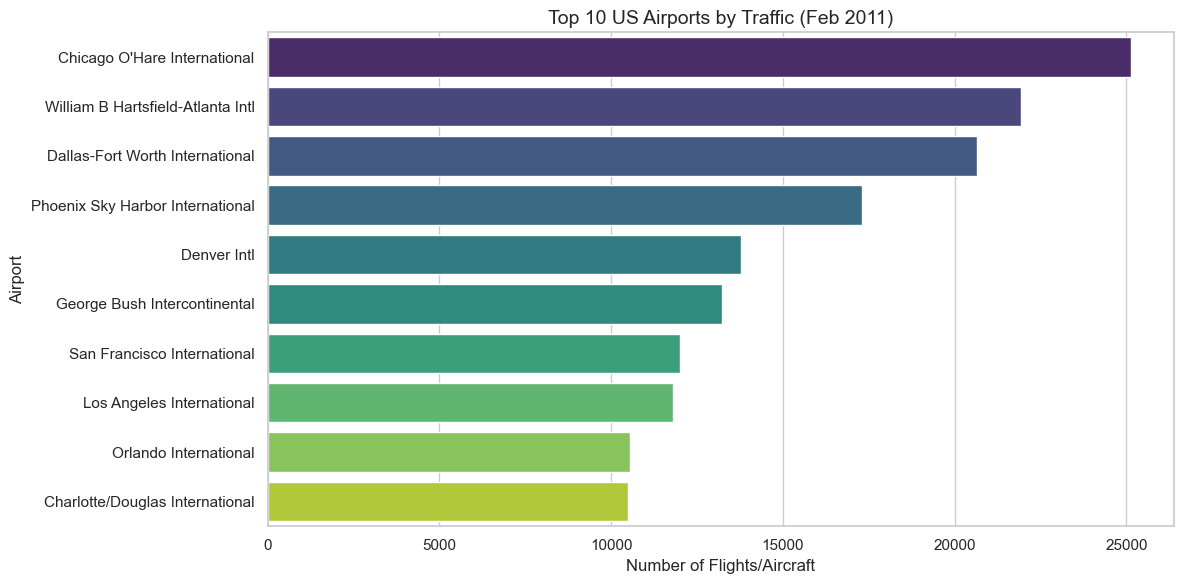

In [10]:
plt.figure(figsize=(12, 6))

# Agregamos hue='airport' y legend=False para quitar el warning
sns.barplot(data=top_airports, x='cnt', y='airport', hue='airport', palette='viridis', legend=False)

plt.title('Top 10 US Airports by Traffic (Feb 2011)', fontsize=14)
plt.xlabel('Number of Flights/Aircraft')
plt.ylabel('Airport')
plt.tight_layout()

import os
os.makedirs('../reports', exist_ok=True)
plt.savefig('../reports/01_top_airports.png', dpi=300, bbox_inches='tight')

plt.show()

In [11]:
import plotly.express as px

# Primero, agrupamos el tráfico total por estado
df_states = df_clean.groupby('state')['cnt'].sum().reset_index()

# Mapa Coroplético (Mapa de calor por estado)
fig = px.choropleth(
    df_states,
    locations='state', # Columna con las abreviaturas de los estados (ej: CA, NY, TX)
    locationmode="USA-states", # Le dice a Plotly que son estados de EE. UU.
    color='cnt', # El color depende del tráfico total
    scope="usa",
    color_continuous_scale="Turbo", # Escala de colores profesional
    title="Total Air Traffic by State (Feb 2011)",
    labels={'cnt':'Total Traffic', 'state':'State'}
)

# Ajustar el diseño para que parezca un tablero profesional
fig.update_layout(
    title_font_size=20,
    title_x=0.5, # Centrar el título
    geo=dict(
        showframe=False, # Quitar el borde
        showcoastlines=True,
        projection_type='albers usa' # Proyección estándar de EE. UU.
    ),
    margin={"r":0,"t":60,"l":0,"b":0}
)

fig.show()